# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Alya Anjani Kasra
- NIM   : 241011401508
- Kelas : Reg B 05TPLM001

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


RANDOM_STATE = 8  # angka 8 karena NIM  berakhiran 08

In [4]:
# Salin fungsi train_test_split dari materi di sini
# train_test_split:
# this function splits the dataset into training and testing sets based on the specified test size and random state.
# the method takes in the features (X), target variable (y), test size, and random state as inputs and returns the training and testing sets for both features and target variable.
# example usage:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


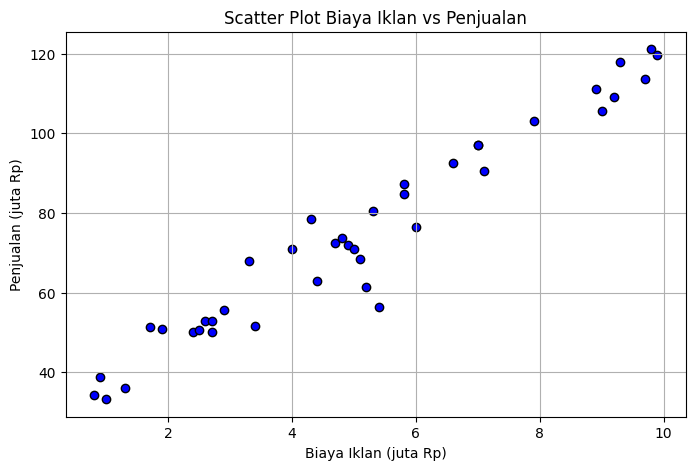

In [7]:
# Load & Visualisasi Data Ads
# 1. Baca file Ads_Data.csv dan tampilkan 5 data pertama beserta jumlah baris
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data:")
print(df_ads.head())
print("\nJumlah baris data:", len(df_ads))

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan). X berbentuk 2 dimensi (n, 1)
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(df_ads['BiayaIklan'], df_ads['Penjualan'], color='blue', edgecolor='k')
plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [9]:
# Buat fungsi train_test_split
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_size = int(n_samples * test_size)
    test_indices = shuffled_indices[:test_size]
    train_indices = shuffled_indices[test_size:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

#  split data untuk Ads
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train_a.shape)
print("Shape X_test :", X_test_a.shape)
print("Shape y_train:", y_train_a.shape)
print("Shape y_test :", y_test_a.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [10]:
#  Training dengan Normal Equation
X_b_train = np.c_[np.ones((len(X_train_a), 1)), X_train_a]
theta = np.linalg.inv(X_b_train.T.dot(X_b_train)).dot(X_b_train.T).dot(y_train_a)
b = theta[0]
m = theta[1]

print(f"Intercept (b) = {b:.4f}")
print(f"Koefisien (m) = {m:.4f}")
print(f"Persamaan garis regresi: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) = 28.9945
Koefisien (m) = 9.0688
Persamaan garis regresi: y_hat = 28.9945 + 9.0688 * X


**Jawaban A3 (interpretasi):**
Setiap kenaikan biaya iklan sebesar 1 juta Rupiah, penjualan toko diperkirakan akan meningkat sebesar 9.0688 juta Rupiah.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [11]:
#  Evaluasi Model (MAE, MSE, RMSE, R2)
def evaluate_regression(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    r2 = 1 - (np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))
    return mae, mse, rmse, r2

# 1. Prediksi pada data training dan testing
y_train_pred = X_b_train.dot(theta)

X_b_test = np.c_[np.ones((len(X_test_a), 1)), X_test_a]
y_test_pred = X_b_test.dot(theta)

# 2. Hitung metrik evaluasi
mae_tr, mse_tr, rmse_tr, r2_tr = evaluate_regression(y_train_a, y_train_pred)
mae_te, mse_te, rmse_te, r2_te = evaluate_regression(y_test_a, y_test_pred)

# 3. Tampilkan dalam bentuk tabel DataFrame
df_eval_a = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Training': [mae_tr, mse_tr, rmse_tr, r2_tr],
    'Testing': [mae_te, mse_te, rmse_te, r2_te]
})

print(df_eval_a)

     Metric   Training    Testing
0       MAE   4.268521   5.361010
1       MSE  28.283550  68.674121
2      RMSE   5.318228   8.286985
3  R2 Score   0.949282   0.915439


**Jawaban A4 (analisis):**
Nilai R2 yang mendekati 1 pada data training dan testing menunjukkan bahwa model regresi linier mampu menjelaskan sebagian besar variasi dari data penjualan berdasarkan biaya iklan. Nilai RMSE juga memberikan gambaran rata-rata besar kesalahan prediksi dalam satuan juta Rupiah yang masih berada dalam batas wajar.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

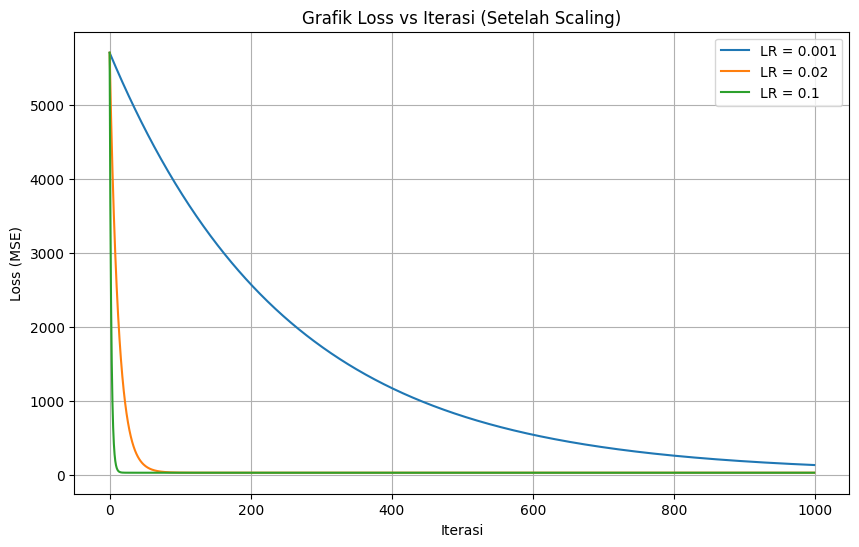

In [12]:
# Definisi kelas LinearRegressionGD
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.array([0.0])
        self.cost_history_ = []

    def fit(self, X, y):
        n_samples = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.cost_history_ = []

        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X.dot(self.coef_)
            error = y_pred - y
            dw = (2/n_samples) * X.T.dot(error)
            db = (2/n_samples) * np.sum(error)

            self.coef_ -= self.learning_rate * dw
            self.intercept_ -= self.learning_rate * db

            mse = np.mean(error ** 2)
            self.cost_history_.append(mse)
        return self

# Normalisasi data X_train_a agar Gradient Descent stabil untuk semua LR
X_train_scaled = (X_train_a - np.mean(X_train_a)) / np.std(X_train_a)

learning_rates = [0.001, 0.02, 0.1]
n_iterations = 1000

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    gd_model = LinearRegressionGD(learning_rate=lr, n_iterations=n_iterations)
    gd_model.fit(X_train_scaled, y_train_a)
    plt.plot(gd_model.cost_history_, label=f'LR = {lr}')

plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.title('Grafik Loss vs Iterasi (Setelah Scaling)')
plt.legend()
plt.grid(True)
plt.show()

Jawaban A5 (analisis):Learning Rate 0.001 (Terlalu kecil): Garis loss turun sangat lambat. Langkah pembaruan bobot terlalu kecil sehingga model membutuhkan waktu/iterasi yang jauh lebih banyak untuk mencapai titik konvergen.

Learning Rate 0.02 (Optimal): Garis loss turun dengan mulus, stabil, dan konvergen ke titik minimum secara efisien dalam jumlah iterasi yang wajar.

Learning Rate 0.1 (Cepat/Agak besar): Garis loss turun sangat tajam di awal iterasi. Ini menunjukkan proses pembelajaran berjalan sangat cepat, namun jika nilainya terlalu besar bisa berisiko melewati titik minimum (overshooting).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

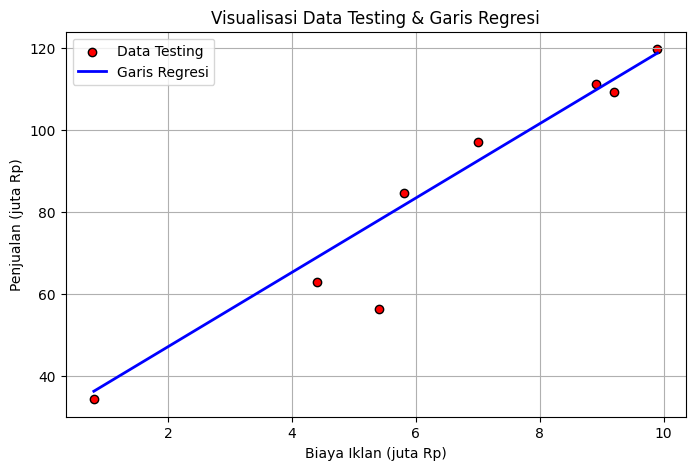

Hasil Prediksi Penjualan:
- Biaya Iklan 4.5 juta -> Prediksi Penjualan: 69.8041 juta Rp
- Biaya Iklan 7.0 juta -> Prediksi Penjualan: 92.4761 juta Rp
- Biaya Iklan 12.0 juta -> Prediksi Penjualan: 137.8202 juta Rp


In [13]:
#  Visualisasi Garis Regresi pada Data Testing & Prediksi

# 1. Visualisasi scatter plot data testing dan garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing', edgecolor='k')

# Urutan X_test agar garis regresi terhubung
sort_idx = X_test_a.flatten().argsort()
y_test_pred_a6 = b + m * X_test_a.flatten()
plt.plot(X_test_a.flatten()[sort_idx], y_test_pred_a6[sort_idx], color='blue', linewidth=2, label='Garis Regresi')

plt.title('Visualisasi Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi penjualan untuk Biaya Iklan = 4.5 juta, 7 juta, dan 12 juta
biaya_baru = np.array([4.5, 7.0, 12.0])
prediksi_penjualan = b + m * biaya_baru

print("Hasil Prediksi Penjualan:")
for b_iklan, p_jual in zip(biaya_baru, prediksi_penjualan):
    print(f"- Biaya Iklan {b_iklan} juta -> Prediksi Penjualan: {p_jual:.4f} juta Rp")

**Jawaban A6 (analisis):** Garis regresi pada data testing terlihat mampu merepresentasikan tren kenaikan data dengan baik. Untuk prediksi biaya iklan sebesar 12 juta, nilainya berada di luar rentang data historis (ekstrapolasi).

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Baris Pertama Email Data:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Email Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


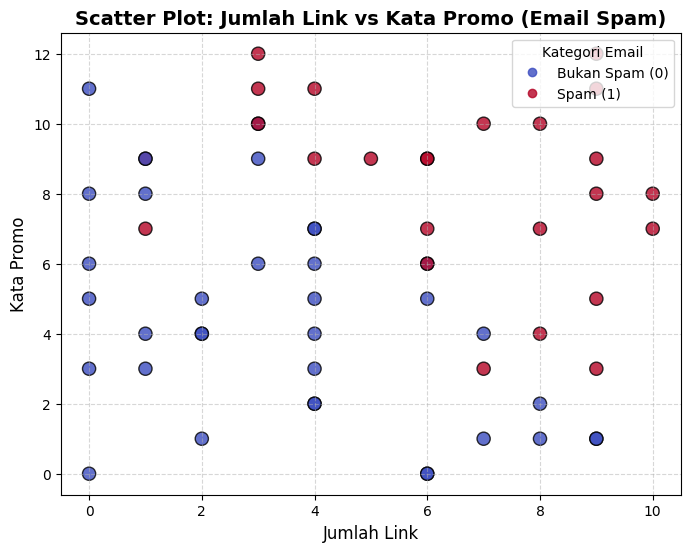

In [14]:
#  Load Dataset Logistic Regression
email_df = pd.read_csv('Email_Data.csv')

print("5 Baris Pertama Email Data:")
display(email_df.head())

print("\nJumlah Email Spam dan Bukan Spam:")
print(email_df['Spam'].value_counts())

# 2. Tentukan fitur (X) dan target (y)
X_email = email_df[['JumlahLink', 'KataPromo']]
y_email = email_df['Spam']

# 3. Membuat Scatter Plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    email_df['JumlahLink'],
    email_df['KataPromo'],
    c=email_df['Spam'],
    cmap='coolwarm',
    edgecolors='k',
    s=90,
    alpha=0.8
)

plt.xlabel('Jumlah Link', fontsize=12)
plt.ylabel('Kata Promo', fontsize=12)
plt.title('Scatter Plot: Jumlah Link vs Kata Promo (Email Spam)', fontsize=14, fontweight='bold')

# Menambahkan Legend & Grid
handles, labels = scatter.legend_elements()
plt.legend(handles, ['Bukan Spam (0)', 'Spam (1)'], title="Kategori Email", loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

=== HASIL PELATIHAN MODEL ===
Intercept (b)      : -8.4338
Koefisien (m1, m2) : [0.7611711  0.72551993]
Persamaan          : P(Spam) = sigma(-8.4338 + 0.7612 * JumlahLink + 0.7255 * KataPromo)


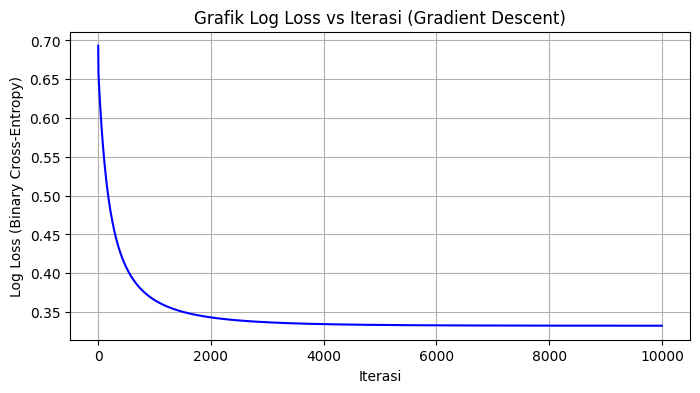

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Load dataset email
df_email = pd.read_csv('Email_Data.csv')
X_email = df_email.iloc[:, :-1].values
y_email = df_email.iloc[:, -1].values

# 2. Split data dengan test_size = 0.25
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

# 3. Kelas Logistic Regression Manual
class LogisticRegressionManual:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.cost_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.cost_history = []

        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            epsilon = 1e-15
            y_predicted = np.clip(y_predicted, epsilon, 1 - epsilon)
            cost = -np.mean(y * np.log(y_predicted) + (1 - y) * np.log(1 - y_predicted))
            self.cost_history.append(cost)

        return self

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

# Latih model dengan learning_rate=0.1 dan n_iterations=10000
log_reg = LogisticRegressionManual(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train_b, y_train_b)

# Tampilkan Intercept (b) dan Koefisien (m1, m2)
print("=== HASIL PELATIHAN MODEL ===")
print(f"Intercept (b)      : {log_reg.bias:.4f}")
print(f"Koefisien (m1, m2) : {log_reg.weights}")
print(f"Persamaan          : P(Spam) = sigma({log_reg.bias:.4f} + {log_reg.weights[0]:.4f} * JumlahLink + {log_reg.weights[1]:.4f} * KataPromo)")

# 4. Buat grafik log loss vs iterasi
plt.figure(figsize=(8, 4))
plt.plot(range(log_reg.n_iterations), log_reg.cost_history, color='b')
plt.title('Grafik Log Loss vs Iterasi (Gradient Descent)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss (Binary Cross-Entropy)')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):** Berdasarkan hasil pelatihan model Logistic Regression, diperoleh persamaan probabilitas yang menunjukkan bahwa bertambahnya jumlah tautan dan kata promosi memperbesar peluang email terdeteksi sebagai spam. Selain itu, grafik Log Loss vs Iterasi memperlihatkan penurunan kurva yang mulus dari angka 0.7 hingga stabil di  0.33, yang membuktikan bahwa proses Gradient Descent berjalan dengan baik dan model berhasil belajar secara optimal untuk meminimalkan tingkat kesalahan.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [16]:
# Implementasi Evaluasi Model Klasifikasi Manual
def manual_confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tn, fp, fn, tp

def evaluate_classification(y_true, y_pred):
    tn, fp, fn, tp = manual_confusion_matrix(y_true, y_pred)

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return accuracy, precision, recall, f1, np.array([[tn, fp], [fn, tp]])

#  prediksi pada data testing email
y_test_pred_b = log_reg.predict(X_test_b)

# Hitung metrik evaluasi
acc, prec, rec, f1, cm = evaluate_classification(y_test_b, y_test_pred_b)

print("=== HASIL EVALUASI MODEL KLASIFIKASI ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)

=== HASIL EVALUASI MODEL KLASIFIKASI ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000

Confusion Matrix:
[[12  0]
 [ 0  3]]


**Jawaban B3 (analisis):** Arti False Positive (FP): Terjadi ketika email yang sebenarnya bukan spam (email penting/masuk) salah diprediksi oleh sistem sebagai spam, sehingga email tersebut masuk ke folder spam.

Arti False Negative (FN): Terjadi ketika email yang sebenarnya adalah spam lolos dari filter dan masuk ke inbox utama pengguna.

Kesalahan yang Lebih Merugikan:

Menurut saya, False Positive (FP) jauh lebih merugikan bagi pengguna karena jika terjadi False Positive, email penting yang sifatnya krusial (seperti urusan pekerjaan, tugas kuliah, atau tagihan) bisa terlewat atau tidak dibaca oleh pengguna karena masuk ke folder spam. Sebaliknya, jika terjadi False Negative (spam masuk ke inbox), pengguna hanya terganggu sebentar dan cukup menghapusnya secara manual tanpa risiko kehilangan informasi penting.





### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

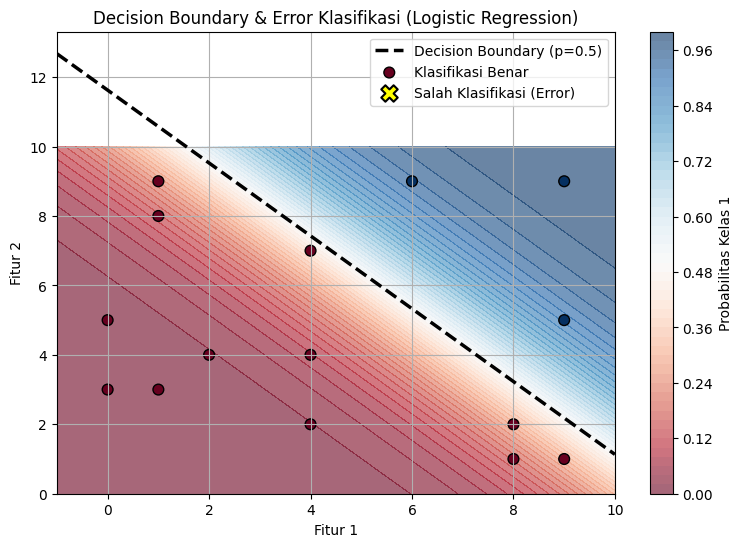

In [17]:
# Visualisasi Decision Boundary dan Garisnya
plt.figure(figsize=(9, 6))

#  2 fitur pertama untuk visualisasi 2D
X_vis = X_test_b[:, :2]
y_vis = y_test_b

#  meshgrid untuk contour background probabilitas
x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

grid_points = np.c_[xx.ravel(), yy.ravel()]
if X_test_b.shape[1] > 2:
    extra_zeros = np.zeros((grid_points.shape[0], X_test_b.shape[1] - 2))
    grid_eval = np.c_[grid_points, extra_zeros]
else:
    grid_eval = grid_points

probs = log_reg.predict_proba(grid_eval).reshape(xx.shape)

# 1. Plot contourf background probabilitas
plt.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.6)
plt.colorbar(label='Probabilitas Kelas 1')

# 2. Plot GARIS DECISION BOUNDARY (saat probabilitas = 0.5 atau z = 0)
# Rumus: x2 = - (bias + weights[0]*x1) / weights[1]
w0, w1 = log_reg.weights[0], log_reg.weights[1]
b_bias = log_reg.bias
x1_vals = np.array([x_min, x_max])
x2_vals = - (b_bias + w0 * x1_vals) / w1
plt.plot(x1_vals, x2_vals, color='black', linewidth=2.5, linestyle='--', label='Decision Boundary (p=0.5)')

# 3. Plot data testing asli & tanda error kalau ada aja
predictions = log_reg.predict(X_test_b)
misclassified = (predictions != y_vis)

plt.scatter(X_vis[~misclassified, 0], X_vis[~misclassified, 1],
            c=y_vis[~misclassified], cmap='RdBu', edgecolor='k', s=60, label='Klasifikasi Benar')

plt.scatter(X_vis[misclassified, 0], X_vis[misclassified, 1],
            color='yellow', marker='X', s=140, edgecolor='black', linewidth=1.5, label='Salah Klasifikasi (Error)')

plt.title('Decision Boundary & Error Klasifikasi (Logistic Regression)')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

**Jawaban B4 (analisis):** Garis decision boundary memisahkan ruang fitur menjadi dua wilayah prediksi (probabilitas 0.5).Titik-titik dengan tanda silang kuning ($\times$) menunjukkan data testing yang salah diklasifikasikan (misclassified), yaitu titik-titik yang posisinya berada di sisi wilayah warna yang salah berdasarkan label aslinya. Hal ini menunjukkan batas kemampuan model linier dalam memisahkan data secara sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [18]:
#Eksperimen Threshold (0.3, 0.5, 0.7)
thresholds = [0.3, 0.5, 0.7]
eval_results = []

#  probabilitas untuk data testing
y_probs = log_reg.predict_proba(X_test_b)

for th in thresholds:
    #  prediksi berdasarkan threshold tertentu
    y_pred_th = (y_probs >= th).astype(int)

    # Hitung metrik evaluasi
    tn, fp, fn, tp = manual_confusion_matrix(y_test_b, y_pred_th)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    eval_results.append({
        'Threshold': th,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

# dalam bentuk DataFrame
df_threshold_eval = pd.DataFrame(eval_results)
display(df_threshold_eval[['Threshold', 'Precision', 'Recall', 'F1-Score', 'TN', 'FP', 'FN', 'TP']])

,Threshold,Precision,Recall,F1-Score,TN,FP,FN,TP
0,0.3,0.75,1.0,0.857143,11,1,0,3
1,0.5,1.00,1.0,1.000000,12,0,0,3
2,0.7,1.00,1.0,1.000000,12,0,0,3


**Jawaban B5 (analisis):** Menurunkan threshold (misal ke 0.3): Model akan lebih mudah melabeli suatu email sebagai spam. Akibatnya, Recall akan meningkat (semakin banyak spam asli yang berhasil tertangkap), namun Precision akan menurun karena jumlah False Positive (email penting yang masuk ke folder spam) ikut bertambah.

Menaikkan threshold (misal ke 0.7): Model menjadi lebih ketat/konservatif dalam melabeli spam. Akibatnya, Precision akan meningkat (sedikit sekali email penting yang salah masuk ke spam), namun Recall akan menurun karena banyak spam lolos ke inbox (False Negative bertambah).

Berdasarkan analisis saya pada Soal B3 di mana False Positive (email penting masuk spam) sangat merugikan pengguna, maka threshold yang lebih tinggi (seperti 0.7) atau threshold standar (0.5) lebih disarankan agar meminimalisir kesalahan pelabelan email penting. Namun, jika ingin lebih aman dari email spam yang lolos, threshold dapat diturunkan ke 0.3 dengan catatan pengguna harus siap sering memeriksa folder spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [19]:
# Jawaban B6: Prediksi untuk Data Email Baru
# Data email baru [JumlahLink, KataPromo]
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

#  threshold dari Soal B5 (misalnya 0.5)
chosen_threshold = 0.5

# Hitung probabilitas dan prediksi kelas
prob_spam = log_reg.predict_proba(email_baru)
pred_kelas = (prob_spam >= chosen_threshold).astype(int)

# Tampilkan hasilnya dalam bentuk DataFrame
import pandas as pd
df_pred_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': email_baru[:, 0],
    'KataPromo': email_baru[:, 1],
    'Probabilitas Spam': prob_spam,
    'Prediksi Kelas (0=Normal, 1=Spam)': pred_kelas
})

display(df_pred_baru)

,Email,JumlahLink,KataPromo,Probabilitas Spam,"Prediksi Kelas (0=Normal, 1=Spam)"
0,E1,1,2,0.001982,0
1,E2,5,6,0.431726,0
2,E3,9,10,0.996571,1
3,E4,2,11,0.744459,1


Berdasarkan model Logistic Regression yang telah dilatih, email dengan jumlah link dan kata promo yang tinggi (seperti E3 dan E4) menghasilkan probabilitas mendekati 1.0 sehingga diklasifikasikan sebagai Spam (1), sementara email dengan jumlah link dan kata promo yang rendah (seperti E1) diklasifikasikan sebagai Bukan Spam / Normal (0).

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression dinamakan "regression" karena menggunakan prinsip dasar regresi linier untuk menghitung kombinasi linear dari fitur input.

**Jawaban C2:** Normal equation menghitung parameter bobot secara langsung menggunakan rumus matematis matriks tanpa proses iterasi, tapi menjadi sangat lambat atau tidak efisien jika jumlah fitur atau ukuran data sangat besar. begitu juga, gradient descent mencari nilai optimal secara bertahap melalui proses iterasi pembaruan bobot

**Jawaban C3:** Model harus dievaluasi pada data testing untuk mengukur kemampuan generalisasi model terhadap data baru yang belum pernah dilihat sebelumnya. Jika dievaluasi pada data training, performa model akan tampak sangat tinggi karena model cenderung menghafal data tersebut (memorization). Overfitting adalah kondisi di mana model terlalu kompleks sehingga menghafal seluruh detail dan noise pada data training, yang berakibat pada buruknya kemampuan prediksi saat dihadapkan pada data baru.

**Jawaban C4:** Linear Regression menggunakan MSE (Mean Squared Error) karena target keluarannya berupa nilai kontinu tanpa batas, sehingga cocok diukur berdasarkan besarnya jarak kuadrat antara prediksi dan nilai asli. Di sisi lain, Logistic Regression menghasilkan output berupa probabilitas (antara 0 dan 1). Jika menggunakan MSE pada probabilitas, fungsi cost-nya akan menjadi tidak konveks, sehingga digunakan log loss agar permukaan fungsi cost berbentuk konveks dan mudah dioptimalkan oleh gradient descent.

**Jawaban C5:** Perbedaan hasil angka seperti koefisien atau akurasi dapat terjadi karena perbedaan konfigurasi parameter acak, seperti nilai random_state pada fungsi pembagian data (train_test_split). Selain itu, variasi dalam pemilihan hyperparameter awal (seperti learning rate, jumlah iterasi, atau teknik scaling) dapat mengarahkan proses gradient descent menuju titik optimum lokal atau jalur konvergensi yang sedikit berbeda.   

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [20]:
# Jawaban Bonus: Perbandingan dengan Scikit-Learn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Perbandingan Linear Regression (Bagian A)
sk_lin_reg = LinearRegression()
sk_lin_reg.fit(X_train_a, y_train_a)

print("=== PERBANDINGAN LINEAR REGRESSION ===")
print(f"Manual (m)  : {m:.4f} | Sklearn (coef_): {sk_lin_reg.coef_[0]:.4f}")
print(f"Manual (b)  : {b:.4f} | Sklearn (intercept_): {sk_lin_reg.intercept_:.4f}")

# 2. Perbandingan Logistic Regression (Bagian B)
# Catatan: Sksklearn secara default menggunakan regularisasi L2 (penalty='l2') dengan nilai C tertentu.
sk_log_reg = LogisticRegression(penalty='l2', C=1.0, random_state=RANDOM_STATE)
sk_log_reg.fit(X_train_b, y_train_b)

sk_pred_b = sk_log_reg.predict(X_test_b)
sk_acc = accuracy_score(y_test_b, sk_pred_b)

print("\n=== PERBANDINGAN LOGISTIC REGRESSION ===")
print(f"Manual Weights : {log_reg.weights}")
print(f"Sklearn Coefs  : {sk_log_reg.coef_}")
print(f"Sklearn Accuracy: {sk_acc:.4f}")

=== PERBANDINGAN LINEAR REGRESSION ===
Manual (m)  : 9.0688 | Sklearn (coef_): 9.0688
Manual (b)  : 28.9945 | Sklearn (intercept_): 28.9945

=== PERBANDINGAN LOGISTIC REGRESSION ===
Manual Weights : [0.7611711  0.72551993]
Sklearn Coefs  : [[0.7004612  0.67552045]]
Sklearn Accuracy: 1.0000


**Jawaban Bonus (analisis):** Perbedaan Koefisien: Koefisien antara model manual (menggunakan Gradient Descent) dan Scikit-learn bisa sedikit berbeda. Pada Scikit-learn, Logistic Regression secara default menerapkan regularisasi L2 (dikontrol oleh parameter penalty dan C) serta menggunakan algoritma solver yang dioptimalkan secara matematis (seperti lbfgs atau liblinear), sedangkan model manual kita murni menggunakan gradient descent tanpa penalti regularisasi.   

Performa Evaluasi: Hasil akurasi atau metrik evaluasi keduanya akan sangat mirip atau mendekati sama karena menggunakan data training dan testing yang identik, meskipun model pustaka bawaan sklearn cenderung lebih stabil karena konvergensi solver-nya diatur secara otomatis.